# Stats 21 - HW4: Palmer Penguins, Summaries, and Plots

## Dennis Huang

Practice turning a question into a pandas analysis and a clearly explained plot.
The central questions are: **Which records contribute, what does a summary mean,
and what can we learn from comparing groups?**


## Academic Integrity

This homework is practice for building your own understanding. Work through the problems, check your reasoning, and use permitted help to support your learning.

Replace `Dennis Huang` to acknowledge the following:

> I, Dennis Huang, agree to follow the course academic integrity policies and the Stats 21 AI and Collaboration Policy. My submitted work reflects my own thinking and understanding, and I can explain my code and results.

**Acknowledgments and AI disclosure:** Credit any people or sources you relied on, and disclose any AI assistance (including hints, debugging, or editing). Briefly state which problems they helped with and how, or write "None".

[Your acknowledgments and AI disclosure here.]

---
Dennis Huang

### Setup and submission

- Use pandas for data preparation, Matplotlib for Part 6, seaborn for Parts 7 and 8, and either pandas plotting or Matplotlib for Part 9.
- Review lectures 13–15 and 17–18.
- Complete the code and short written responses (1–2 sentences are usually enough unless specified otherwise). Use code to calculate requested results rather than hardcoding values.
- Keep `penguins.csv` in the same directory as this notebook. Use this supplied file rather than loading the dataset from seaborn, as this version includes the `year` column.
- Before submitting, restart the kernel and run all cells from top to bottom so all tables, plots, and written responses are visible.
- Export to HTML, print to a letter-sized PDF, and submit the PDF to Gradescope with pages assigned to each question. Submit your completed `.ipynb` file as well.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 3)


### About the data

Each row represents a single penguin record. `species`, `island`, and `sex` describe groups, and `year` records the study year. Bill length, bill depth, and flipper length are measured in millimeters; body mass is in grams.

The data were collected by Kristen Gorman and the Palmer Station LTER program. See the [Palmer Penguins data dictionary](https://allisonhorst.github.io/palmerpenguins/reference/penguins.html) for details.


In [2]:
penguins = pd.read_csv("penguins.csv")

# Use these four physical measurements for the requested numeric summaries.
measurement_cols = [
    "bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"
]
species_order = ["Adelie", "Chinstrap", "Gentoo"]

penguins.head()


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


### Part 1) Inspect the data

Use the original `penguins` table.

a. Display its shape and state what one row represents.

b. Display the column names and data types. Which numeric column records the study year rather than a physical measurement? Why shouldn't data type alone determine which columns belong in a summary of penguin size?

c. Display the number of missing values in each column.

d. Count records by `species` and by `sex`, including missing values (`value_counts(dropna=False)`). Verify that each set of counts adds up to the total number of rows.


In [3]:
# Part 1: inspect the original table and display the requested counts.

# A
print("Part A")
print(penguins.shape)
# B
print("Part B")
print(penguins.dtypes)
# C
print("Part C")
print(penguins.isna().sum())
# D
print("Part D")
print(penguins[["species", "sex"]].value_counts(dropna=False))



Part A
(344, 8)
Part B
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object
Part C
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64
Part D
species    sex   
Adelie     male      73
           female    73
Gentoo     male      61
           female    58
Chinstrap  female    34
           male      34
Adelie     NaN        6
Gentoo     NaN        5
Name: count, dtype: int64


**Written response:**

Part A:
One row represents one individual penguin and the data taken from it.

Part B:
Numeric column "year" records the study year. Data type alone should not determine which columns belong in a summary of penguin size as different columns, with different data types, could be used to measure penguin size.

Part C:
73 + 73 +61 + 58 +34 + 34 +6 + 5  = 344 

### Part 2) Missing data: choose rows for the question

Do not modify the original `penguins` DataFrame in place.

a. Create `penguins_clean` by dropping rows missing any of the four `measurement_cols` or `sex` (use `.dropna(subset=...).copy()`). Display its shape and the number of rows removed.

b. Create `penguins_bill` from `penguins` by dropping only rows missing `bill_length_mm`, `bill_depth_mm`, or `species`, keeping all columns. Display its shape and how many more records it retains than `penguins_clean`.

c. For a plot of bill length versus bill depth colored by species, which subset is more appropriate? Explain why a missing value for `sex` should or should not exclude a record from this plot.

*Note: `penguins_clean` is only for comparison here. In the parts that follow, filter `penguins` (or use `penguins_bill` where specified) based only on the variables needed for that question.*


In [4]:
# Part 2: construct the two subsets and compare their row counts.
# Used Gemini for help debugging error "TypeError: DataFrame.dropna() takes 1 positional argument but 2 were given". Hint lead me to create one clean list using +.
# Asked Gemini for help getting the number of rows removed, to which it hinted at using the len() function.
# A
print("Part A")
penguins_clean = penguins.dropna(subset = measurement_cols + ["sex"]).copy()
print(penguins_clean)
print("Removed Rows: " + str(len(penguins)- len(penguins_clean)))

# B 
print("Part B")
penguins_bill = penguins.dropna(subset = ["bill_length_mm", "bill_depth_mm", "species"]).copy()
print(penguins_bill)
penguins_bill.shape
print("Number of Records contained in penguins_bill than penguins_clean: " + str(len(penguins_bill)- len(penguins_clean)))



Part A
       species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0       Adelie  Torgersen            39.1           18.7              181.0   
1       Adelie  Torgersen            39.5           17.4              186.0   
2       Adelie  Torgersen            40.3           18.0              195.0   
4       Adelie  Torgersen            36.7           19.3              193.0   
5       Adelie  Torgersen            39.3           20.6              190.0   
..         ...        ...             ...            ...                ...   
339  Chinstrap      Dream            55.8           19.8              207.0   
340  Chinstrap      Dream            43.5           18.1              202.0   
341  Chinstrap      Dream            49.6           18.2              193.0   
342  Chinstrap      Dream            50.8           19.0              210.0   
343  Chinstrap      Dream            50.2           18.7              198.0   

     body_mass_g     sex  year  
0         3

**Written response:**

Part C:
For a plot of bill length vs bill depth colored by species, penguins bill is the better subset. This is because penguin_bill contains information about species, which is needed, while penguin_clean has addition information about sex which will not be used in the plot.


### Part 3) Numeric summaries and a small wrangling task

Use `penguins`, retaining rows with missing values.

a. Use `.describe()` on `measurement_cols` to show the count, mean, standard deviation, minimum, quartiles, and maximum. Explain what `count` represents and why it can differ from the total number of rows.

b. Compute the mean and standard deviation of `measurement_cols` within each species.

c. Add a `body_mass_kg` column to `penguins` by converting grams to kilograms. Filter for Gentoo penguins from 2008 with a recorded body mass. Display the total number of matching records, and show `species`, `island`, `year`, and `body_mass_kg` for the five heaviest penguins sorted from heaviest to lightest.


In [5]:
# Part 3: summarize measurements, create kilograms, then filter/select/sort.
# A
print("part A")
print(penguins[measurement_cols].describe())
# B 
print("part B")
print(penguins.groupby("species")[measurement_cols].mean())
print(penguins.groupby("species")[measurement_cols].std())
# C 
penguins["body_mass_kg"] = penguins["body_mass_g"]/1000
gento_penguins = penguins[(penguins["species"] == "Gentoo") & (penguins["year"] ==  2008) & (penguins["body_mass_kg"].notna())] 
print("Total number of matching records: " + str(len(gento_penguins)))
print(gento_penguins.sort_values("body_mass_kg", ascending = False).head(5)[["species", "island", "year", "body_mass_kg"]])

part A
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count         342.000        342.000            342.000      342.000
mean           43.922         17.151            200.915     4201.754
std             5.460          1.975             14.062      801.955
min            32.100         13.100            172.000     2700.000
25%            39.225         15.600            190.000     3550.000
50%            44.450         17.300            197.000     4050.000
75%            48.500         18.700            213.000     4750.000
max            59.600         21.500            231.000     6300.000
part B
           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
species                                                                 
Adelie             38.791         18.346            189.954     3700.662
Chinstrap          48.834         18.421            195.824     3733.088
Gentoo             47.505         14.982            217.187     5076.016


**Written response:**

Part A:
Count represents the total number of rows minus rows missing values, which is why it can differ from the total number of rows.


### Part 4) Two-way grouped summaries

Use `penguins` and group by `species` and `sex`, keeping missing-sex groups with `groupby(..., dropna=False)`.

a. Produce a summary table with one row per species/sex combination that includes the total row count (`n_penguins`, using `size`) and the mean and nonmissing count (`count`) for each of the four `measurement_cols`.

b. Verify that `n_penguins` sums to the total number of rows in `penguins`. For one of the unknown-sex groups, compare `n_penguins` with its nonmissing `body_mass_g` count. Explain why they differ and which count serves as the denominator when computing mean body mass.

c. Among groups with recorded sex, identify the species/sex group with the largest mean body mass and display its summary row. Does having the largest group mean imply that every penguin in that group is heavier than every penguin in the other groups? Explain briefly.


In [6]:
# Part 4: keep unknown-sex groups and distinguish size from count.

# A 
print("part A")
summarytable = penguins.groupby(["species", "sex"], as_index=False, dropna=False).agg(n_penguins = ("species","size"),
         bill_length_mean = ("bill_length_mm", "mean"),
         bill_length_count = ("bill_length_mm", "count"),
         bill_depth_mean = ("bill_depth_mm", "mean"),
         bill_depth_count = ("bill_depth_mm", "count"),
         flipper_length_mean = ("flipper_length_mm", "mean"),
         flipper_length_count = ("flipper_length_mm", "count"),
         body_mass_g_mean = ("body_mass_g", "mean"),
         body_mass_g_count = ("body_mass_g", "count"),)
print(summarytable)
# B 
print("part B")
print("N_penguins sums to the total number of rows in penguins: " + str(summarytable["n_penguins"].sum() == len(penguins)))

unknown_sex_group = summarytable[summarytable["sex"].isna()]
print(unknown_sex_group[["species", "sex", "n_penguins", "body_mass_g_count"]])


# C
print("part C")
recorded_sex = summarytable[summarytable["sex"].notna()]
print(recorded_sex.sort_values("body_mass_g_mean", ascending = False).head(1))

part A
     species     sex  n_penguins  bill_length_mean  bill_length_count  \
0     Adelie  female          73            37.258                 73   
1     Adelie    male          73            40.390                 73   
2     Adelie     NaN           6            37.840                  5   
3  Chinstrap  female          34            46.574                 34   
4  Chinstrap    male          34            51.094                 34   
5     Gentoo  female          58            45.564                 58   
6     Gentoo    male          61            49.474                 61   
7     Gentoo     NaN           5            45.625                  4   

   bill_depth_mean  bill_depth_count  flipper_length_mean  \
0           17.622                73              187.795   
1           19.073                73              192.411   
2           18.320                 5              185.600   
3           17.588                34              191.735   
4           19.253            

**Written response:**

[Write your interpretation here.]

Part B:
They differ because using size to extract from n_penguins includes rows with missing values, while count excludes these rows. We should use count as the denominator because non-missing values do not add anything to the added sum of the demoninator of the mean.

Part C:
The Gentoo male is, on average, has the largest mean body mass. No, having the largest mean body mass does not mean every gentoo penguin is bigger than others, as the mean only takes the average weight of all penguins and compares it to others. This does not account for individual 
within the groups.

### Part 5) Correlations and Simpson's paradox

Use `penguins_bill` and `measurement_cols`.

a. Compute the Pearson correlation matrix for the four measurements, first across all penguins pooled together, and then separately within each species (`groupby("species")[measurement_cols].corr()`).

b. Focus on **bill length and bill depth**. Create a compact summary table showing their pooled correlation, their correlation within each species, and the number of paired records used in each calculation.

c. Compare the signs of the correlations. A *Simpson's paradox reversal* occurs when the pooled association has the opposite sign from the association within each individual group. State whether your results show this reversal, citing the correlation values.


In [7]:
# Part 5: show the correlation matrices and a compact bill-pair comparison.

# I had no idea what a pearson correlation matrix was, so I used AI for clarification on what this needs. 
# Asked for various hints making the compact summary table, such as hints on hwo to get started and how to make the summary table. I wans't sure how to get the correlation within each species, for which I asked for clarification in breaking down the question into steps.

print("part A")
print(penguins_bill[measurement_cols].corr())
print(penguins_bill.groupby("species")[measurement_cols].corr())

# B 
print("part B")
bill_stats = penguins_bill.dropna(subset = ["bill_length_mm", "bill_depth_mm"])
pooled_corre = bill_stats["bill_length_mm"].corr(bill_stats["bill_depth_mm"])

chinstrap = bill_stats[bill_stats["species"] == "Chinstrap"]
adelie = bill_stats[bill_stats["species"] == "Adelie"]
gentoo = bill_stats[bill_stats["species"] == "Gentoo"]

c_corre = chinstrap["bill_length_mm"].corr(chinstrap["bill_depth_mm"])
a_corre = adelie["bill_length_mm"].corr(adelie["bill_depth_mm"])
g_corre = gentoo["bill_length_mm"].corr(gentoo["bill_depth_mm"])

bill_summary = pd.DataFrame({"Populations": ["Entire population", "Chinstrap", "Adelie", "Gentoo"], "Correlations": [pooled_corre, c_corre, a_corre, g_corre], "Number": [len(bill_stats),len(chinstrap),len(adelie),len(gentoo)]})
print(bill_summary)

part A
                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
bill_length_mm              1.000         -0.235              0.656   
bill_depth_mm              -0.235          1.000             -0.584   
flipper_length_mm           0.656         -0.584              1.000   
body_mass_g                 0.595         -0.472              0.871   

                   body_mass_g  
bill_length_mm           0.595  
bill_depth_mm           -0.472  
flipper_length_mm        0.871  
body_mass_g              1.000  
                             bill_length_mm  bill_depth_mm  flipper_length_mm  \
species                                                                         
Adelie    bill_length_mm              1.000          0.391              0.326   
          bill_depth_mm               0.391          1.000              0.308   
          flipper_length_mm           0.326          0.308              1.000   
          body_mass_g                 0.549          0.576         

**Written response:**

[Write your interpretation here.]
Part C:
Comparing the correlations of each population, I find it extremely shocking how every correlation of each group composing the penguin population is positive, but the correlation of the entire population itself is negative. This is an exampel of the Simpson's paradox, as every population group as a positive correlation vs the entire population as a whole having a negative correlation. 

## Plots: make the analysis visible

For Parts 6–9:
- Give each figure a descriptive title, axis labels with units, and a legend where appropriate.
- Use comparable axes when comparing panels.
- Report the number of included and excluded records for each plot, dropping only rows that are missing variables required for that specific plot.


### Part 6) Matplotlib histograms of body mass by species

Use rows of `penguins` with nonmissing `body_mass_g` and `species`.

a. Use `plt.subplots(1, 3, ...)` and `ax.hist(...)` to create one panel per species in `species_order`. Share the x- and y-axes and pass the same explicit bin edges (e.g., `range(2500, 6501, 500)`) to all three panels.

b. Plot counts, label body mass in grams, and include each species' sample size ($n$) in its panel title. Report the total number of included and excluded records.

c. In two sentences, compare the distributions across species and explain why a taller histogram can reflect sample size as well as distribution shape. If you set `density=True`, would the total area of the bars or the sum of the bar heights equal 1?


part A


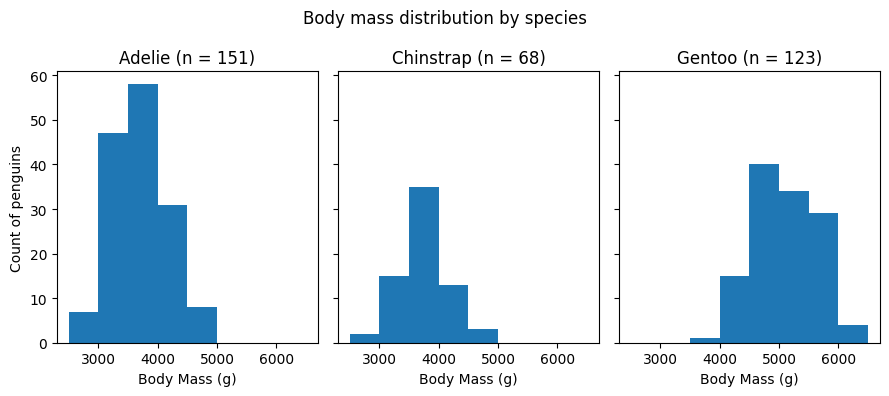

part B
Included: 342
Excluded: 2


In [8]:
# Part 6: choose records, then build three Matplotlib histogram panels.
# Asked Gemini for help debugging my for loop and getting the histograms to correctly show without error. I tried using the lecture 17 examples as references, but kept not working because of various errors.
# A
print("part A")
body_mass = penguins.dropna(subset = ["body_mass_g", "species"]).copy()
bins = range(2500, 6501, 500)

fig, axes = plt.subplots(1,3, figsize = (9, 4), sharex = True,  sharey = True)
for ax, spec in zip(axes, species_order):
    species_mass = body_mass.loc[body_mass["species"] == spec, "body_mass_g"]
    ax.hist(species_mass, bins=bins)
    ax.set_title(spec + " (n = " + str(len(species_mass)) + ")")
    ax.set_xlabel("Body Mass (g)")

axes[0].set_ylabel("Count of penguins")
fig.suptitle("Body mass distribution by species")
plt.tight_layout()
plt.show()

# B 
print("part B")
print("Included: " + str(len(body_mass)))
print("Excluded: " + str(len(penguins) - len(body_mass)))

**Written response:**

[Write your interpretation here.]
Part C:
Comparing the distributions, we can see that the Getto has the highest body mass centers, with Chinstrap and Adelie penguins being closely similar. There are big peaks on the Adelie plot, while the peaks for Chinstrap and Gentoo are relatively similar to each other. There are no outstanding outliers in any of the distributions. A taller histogram can reflect both a larger sample size and details about the distribution, as it can either be used to compare the biggest sample size of a graph, such as with Adelie's higher peaks compared to Chinstrap and Gentoo, or it can showcase where the relative peaks within a distribution are. If you set density = True, the total area of the bars would equal 1. 

### Part 7) Seaborn boxplots of flipper length

Use rows of `penguins` with nonmissing `flipper_length_mm` and `species`.

a. Create a Matplotlib `Axes` and pass it to `sns.boxplot(..., ax=ax)` with `species` (in `species_order`) on the x-axis and `flipper_length_mm` on the y-axis. Report the included/excluded record counts and sample sizes by species.

b. In 2–3 sentences, explain what the box and center line represent, and compare the medians and middle-50% spreads across species. Does a point plotted beyond the whiskers necessarily indicate a data error? Explain briefly.


part A


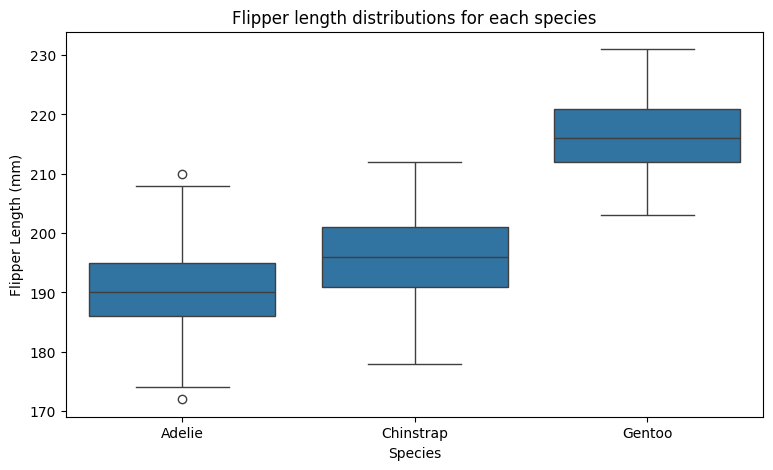

Included 342
Excluded 2
species
Adelie       151
Chinstrap     68
Gentoo       123
dtype: int64


In [9]:
# Part 7: draw seaborn boxplots on a Matplotlib Axes.
# A
print("part A")
flippers = penguins.dropna(subset=["flipper_length_mm", "species"]).copy()
fig, ax = plt.subplots(figsize = (9,5))
sns.boxplot(data=flippers, x="species", y="flipper_length_mm", order=species_order, ax=ax)
ax.set_title("Flipper length distributions for each species")
ax.set_xlabel("Species")
ax.set_ylabel("Flipper Length (mm)")
plt.show()

print("Included " + str(len(flippers)))
print("Excluded " + str(len(penguins)- len(flippers)))
print(flippers.groupby("species").size())


**Written response:**

[Write your interpretation here.]

Part B:
The box represents the 25% and 75% percentiles of the distributions, where the center line represents the exact 50% mark of the distributions. The medians of each species, from lowest to highest, go from Adelie, Chinstrap, then to Gentoo. A plot beyond the whiskers does not necessarily mean a data error, it just means that there are outliers within the data set. 


### Part 8) Scatterplot and fitted lines: bill length versus bill depth

Use `penguins_bill`.

a. Plot `bill_length_mm` (x) versus `bill_depth_mm` (y), colored by `species`, with a separate linear regression line for each species. Include a legend and report the number of included and excluded records.

*Hint: `sns.lmplot(data=..., x=..., y=..., hue="species", ci=None)` plots both the points and fitted lines. Because `lmplot` creates its own figure-level `FacetGrid`, use `g.set_axis_labels(...)` and `g.figure.suptitle(...)` to label the plot (or loop over species with `sns.regplot`).*

b. In 3–4 sentences, explain what a point and a fitted line represent. Connect the slopes of the within-species lines to your correlations in Part 5, and use the relative positions of the three species clusters to explain why the pooled correlation has the opposite sign. Does this plot show that changing a penguin's bill length causes its bill depth to change?


part A


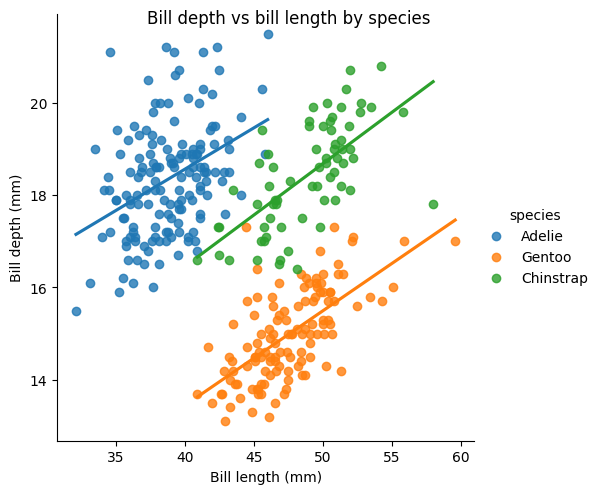

Included: 342
Excluded: 2


In [10]:
# Part 8: draw paired measurements and separate fitted lines by species.
# A
print("part A")
g = sns.lmplot(data=penguins_bill, x="bill_length_mm", y="bill_depth_mm", hue="species", ci=None)
g.set_axis_labels("Bill length (mm)", "Bill depth (mm)")
g.figure.suptitle("Bill depth vs bill length by species")
plt.show()

print("Included: " + str(len(penguins_bill)))
print("Excluded: " + str(len(penguins) - len(penguins_bill)))

**Written response:**

[Write your interpretation here.]

Part B:
Every point on this plot represents one individual penguin's bill length to their bill depth. The fitted lines in the scatterplot represent the line of best fit for each distribution, showing an average of how bill depth changes as bill length increases and vice versa. The pooled sign flips and has the opposite sign, as when you ignore the species and take the enitre plot as a whole, the data actually shows a negative trend for bill length compoared to bill depth. No, a scatterplot of this data shows association, not causation, as causation must be confirmed via isolated experiment.

### Part 9) Stacked bars: recorded sex proportions by species

Create `penguins_sex` from `penguins` by keeping rows with nonmissing `species` and `sex`.

a. Use `pd.crosstab(...)` to create a species-by-sex count table, then normalize each row to proportions using `.div(..., axis=0)`. Display both tables and verify that each row of proportions sums to 1.

b. Create a stacked bar chart in `species_order` showing the male and female proportions for each species (using `.plot.bar(stacked=True, ax=ax)` or `ax.bar(..., bottom=...)`). Label the y-axis as a proportion and include a legend.

c. Report the number of included and excluded records per species, and include the sample sizes ($n$) in your chart labels or title. Briefly compare the sex proportions across species, and explain why bars of equal total height (1.0) do not imply equal sample sizes.

d. In one sentence, explain what would happen if you reset the index of your 3-row count table and passed it directly to `sns.countplot(data=..., x="species")`.


part A
Count Table
sex        female  male
species                
Adelie         73    73
Chinstrap      34    34
Gentoo         58    61
Proportions Table
sex        female   male
species                 
Adelie      0.500  0.500
Chinstrap   0.500  0.500
Gentoo      0.487  0.513
Verify Props = 1
species
Adelie       1.0
Chinstrap    1.0
Gentoo       1.0
dtype: float64
part B


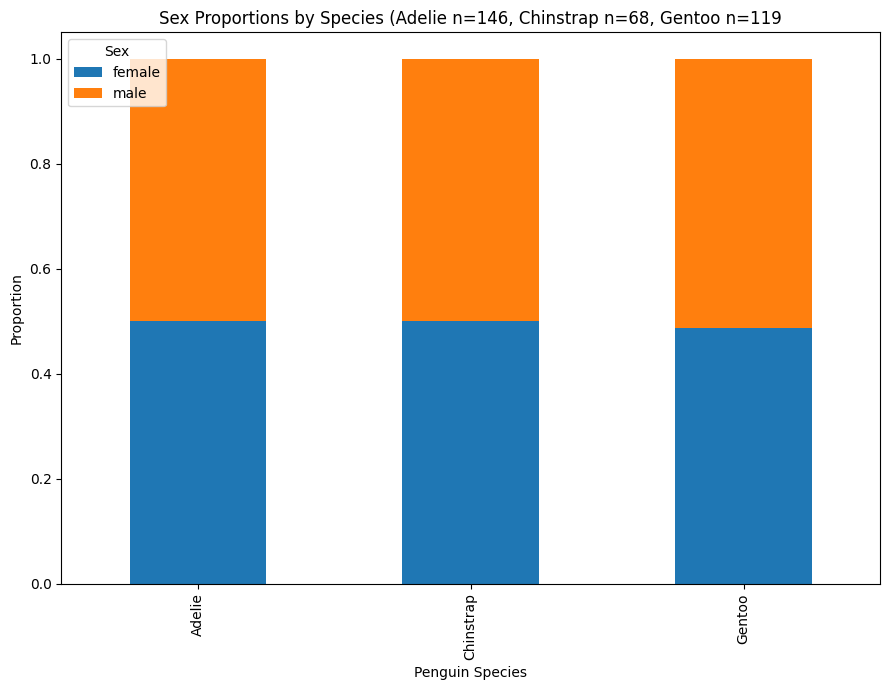

part C
Included per species:
species
Adelie       146
Chinstrap     68
Gentoo       119
dtype: int64
Excluded per species:
species
Adelie       6
Chinstrap    0
Gentoo       5
dtype: int64
Total included:  333
Total excluded:  11


In [11]:
# Part 9: calculate counts and proportions before drawing the stacked bars.
# A
print("part A")
penguins_sex = penguins.dropna(subset=["species", "sex"]).copy()
species_by_sex = pd.crosstab(penguins_sex["species"], penguins_sex["sex"])

sex_props = species_by_sex.div(species_by_sex.sum(axis=1), axis=0)

print("Count Table")
print(species_by_sex)
print("Proportions Table")
print(sex_props)
print("Verify Props = 1")
print(sex_props.sum(axis=1))

# B 
print("part B")
fig, ax = plt.subplots(figsize = (9,7))
sex_props.plot.bar(stacked = True, ax = ax)

ax.set_xlabel("Penguin Species")
ax.set_ylabel("Proportion")
ax.set_title("Sex Proportions by Species (Adelie n=146, Chinstrap n=68, Gentoo n=119")
ax.legend(title="Sex",loc="upper left")

plt.tight_layout()
plt.show()

# C
print("part C")
n_total = penguins.groupby("species").size()
n_included = penguins_sex.groupby("species").size()
n_excluded = n_total - n_included

print("Included per species:")
print(n_included)
print("Excluded per species:")
print(n_excluded)
print("Total included: ", len(penguins_sex))
print("Total excluded: ", len(penguins) - len(penguins_sex))

**Written response:**

[Write your interpretation here.]
Part C: 
The sex proportions of all three species are roughly the same at around 50% female 50% male. Bars of equal height do not imply differing sample sizes, as these bars are made as a proportion of the whole. This means that sample size does not matter, as it is a percentage based on the total popluation. 

Part D: 
If we were to reset the index of our three row table and pass it directly onto sns.countplot, the table would be reset to one row a species. The countplot would count the rows of the newly reset table, which would not contain the sample size data.

### Before submitting

Restart the kernel and run all cells. Make sure all tables, figures, and written responses are visible, and double-check that you completed the academic integrity acknowledgment at the top of the notebook.

Useful references: [pandas aggregation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.agg.html),
[pandas correlations](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html),
[Matplotlib subplots](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html),
and [seaborn regression plots](https://seaborn.pydata.org/generated/seaborn.lmplot.html).
